In [33]:
import pandas as pd
df=pd.read_excel(r"C:\Users\chrishma\Downloads\IDS Data Collection (original).ods",engine="odf")

In [34]:
df.head()

,Age,Daily Screen time,Social media usage,Sleep Duration,Study Time,Favorite Entertainment Platform,Preferred Programming Language,Daily Commute Time,Number of Cups of coffee/Tea per day,Daily Exercise time,Major Distractions
0,19,10 hours,5 hours,10,2 hours,Instagram,Python,30 minutes,0,15 minutes,Phone
1,18,6 hours,3 hours,6 hours,3 hours,YouTube,Python,15 min,1,1hour,Movies
2,19,2 hours,30mins,7 hours,5Hours,Bigboss,Python,20mins,1,1 Hour 30 mins (Morning),Friends
3,18,6 hours,2 hours,7 hours,5 hours,Instagram,Python,1 hour,0,0,Reels
4,19,5 hours,2 hours,7 hours,2 hours,YouTube,Python,30 minutes,0,15 minutes,Mobile


In [35]:
df.columns

Index(['Age', 'Daily Screen time', 'Social media usage ', 'Sleep Duration ',
       'Study Time', 'Favorite Entertainment Platform',
       'Preferred Programming Language ', 'Daily Commute Time',
       'Number of Cups of coffee/Tea per day', 'Daily Exercise time',
       'Major Distractions'],
      dtype='object')

In [36]:
df.shape

(54, 11)

In [37]:
df.isnull().sum()

Age                                     0
Daily Screen time                       0
Social media usage                      0
Sleep Duration                          0
Study Time                              0
Favorite Entertainment Platform         0
Preferred Programming Language          0
Daily Commute Time                      0
Number of Cups of coffee/Tea per day    0
Daily Exercise time                     0
Major Distractions                      0
dtype: int64

In [38]:
df.duplicated().sum()

0

In [39]:
df.dtypes

Age                                      int64
Daily Screen time                       object
Social media usage                      object
Sleep Duration                          object
Study Time                              object
Favorite Entertainment Platform         object
Preferred Programming Language          object
Daily Commute Time                      object
Number of Cups of coffee/Tea per day    object
Daily Exercise time                     object
Major Distractions                      object
dtype: object

In [40]:
df["Daily Screen time"]

0           10 hours 
1            6 hours 
2            2 hours 
3             6 hours
4             5 hours
5            8 hours 
6                   8
7        4 to 5 hours
8                   7
9           4-6 hours
10           10 hours
11            7 hours
12             6-7hrs
13           8 Hours 
14            6 hours
15        10-11 hours
16               5hrs
17            7 hours
18            4 hours
19            8 hours
20                  7
21            6-7 hrs
22                  7
23            6 hours
24             9 hrs 
25                  9
26            6 hours
27                  6
28              6 hrs
29           10 hours
30            8 hours
31            6 hours
32          7-8 hours
33               7 hr
34              7 hrs
35            9 hours
36           8 hours 
37         6 -7 hours
38            8 hours
39      6 - 10 hours 
40            4 hours
41            3 hours
42              5 hrs
43               6hrs
44                 6h
45        

In [41]:
df["Daily Screen time"] = (
    df["Daily Screen time"]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
    .astype(float)
)

In [42]:
df["Daily Screen time"]

0     10.0
1      6.0
2      2.0
3      6.0
4      5.0
5      8.0
6      8.0
7      4.0
8      7.0
9      4.0
10    10.0
11     7.0
12     6.0
13     8.0
14     6.0
15    10.0
16     5.0
17     7.0
18     4.0
19     8.0
20     7.0
21     6.0
22     7.0
23     6.0
24     9.0
25     9.0
26     6.0
27     6.0
28     6.0
29    10.0
30     8.0
31     6.0
32     7.0
33     7.0
34     7.0
35     9.0
36     8.0
37     6.0
38     8.0
39     6.0
40     4.0
41     3.0
42     5.0
43     6.0
44     6.0
45     4.0
46     7.0
47     6.0
48     3.0
49     4.0
50     8.0
51     4.0
52     3.0
53     6.0
Name: Daily Screen time, dtype: float64

In [43]:
df["Daily Screen time"] = df["Daily Screen time"].astype(str) + " hours"

In [44]:
df["Daily Screen time"]

0     10.0 hours
1      6.0 hours
2      2.0 hours
3      6.0 hours
4      5.0 hours
5      8.0 hours
6      8.0 hours
7      4.0 hours
8      7.0 hours
9      4.0 hours
10    10.0 hours
11     7.0 hours
12     6.0 hours
13     8.0 hours
14     6.0 hours
15    10.0 hours
16     5.0 hours
17     7.0 hours
18     4.0 hours
19     8.0 hours
20     7.0 hours
21     6.0 hours
22     7.0 hours
23     6.0 hours
24     9.0 hours
25     9.0 hours
26     6.0 hours
27     6.0 hours
28     6.0 hours
29    10.0 hours
30     8.0 hours
31     6.0 hours
32     7.0 hours
33     7.0 hours
34     7.0 hours
35     9.0 hours
36     8.0 hours
37     6.0 hours
38     8.0 hours
39     6.0 hours
40     4.0 hours
41     3.0 hours
42     5.0 hours
43     6.0 hours
44     6.0 hours
45     4.0 hours
46     7.0 hours
47     6.0 hours
48     3.0 hours
49     4.0 hours
50     8.0 hours
51     4.0 hours
52     3.0 hours
53     6.0 hours
Name: Daily Screen time, dtype: object

In [45]:
df["Social media usage "].value_counts(dropna=False)

Social media usage 
2 hours                                   10
3 hours                                    4
3hrs                                       3
5 hours                                    3
4 hours                                    3
1 and half hour                            2
4 hrs                                      2
3                                          2
2                                          2
1-2 hours                                  2
2 hours                                    2
2 hrs                                      2
5 hr                                       1
5 hours                                    1
1 hour                                     1
1-2 hours                                  1
2hours                                     1
1 hour 30 mins                             1
02:30:00                                   1
3h                                         1
3 hrs                                      1
4                                  

In [46]:
import re

def clean_social_media_time(x):
    x = str(x).strip().lower()

    if x in ["nan", ""]:
        return "Unknown"

    if "30mins" in x or "30 mins" in x:
        return 0.5

    if "1 and half" in x:
        return 1.5

    if ":" in x:
        parts = x.split(":")
        return float(parts[0]) + float(parts[1]) / 60

    numbers = re.findall(r'\d+(?:\.\d+)?', x)

    if numbers:
        return max(map(float, numbers))

    return "Unknown"


df["Social media usage "] = df["Social media usage "].apply(clean_social_media_time)

In [47]:
df["Social media usage "]

0         5.0
1         3.0
2         0.5
3         2.0
4         2.0
5         2.0
6         3.0
7     Unknown
8         2.0
9         2.0
10        5.0
11        4.0
12        3.0
13        3.0
14        2.0
15        4.0
16        3.0
17        2.0
18        2.0
19        3.0
20        2.0
21        3.0
22        3.0
23        2.0
24        2.0
25        3.0
26        2.0
27        4.0
28        4.0
29        2.0
30        4.0
31        1.5
32        2.0
33        5.0
34        4.0
35        3.0
36        2.0
37        3.0
38        2.0
39        4.0
40        1.0
41        2.0
42        2.0
43        3.0
44        3.0
45        1.5
46        5.0
47        3.0
48        2.0
49        2.0
50        0.5
51        2.5
52        1.0
53        5.0
Name: Social media usage , dtype: object

In [48]:
df["Social media usage "] = (
    df["Social media usage "].astype(str) + " hours"
)
df["Social media usage "]

0         5.0 hours
1         3.0 hours
2         0.5 hours
3         2.0 hours
4         2.0 hours
5         2.0 hours
6         3.0 hours
7     Unknown hours
8         2.0 hours
9         2.0 hours
10        5.0 hours
11        4.0 hours
12        3.0 hours
13        3.0 hours
14        2.0 hours
15        4.0 hours
16        3.0 hours
17        2.0 hours
18        2.0 hours
19        3.0 hours
20        2.0 hours
21        3.0 hours
22        3.0 hours
23        2.0 hours
24        2.0 hours
25        3.0 hours
26        2.0 hours
27        4.0 hours
28        4.0 hours
29        2.0 hours
30        4.0 hours
31        1.5 hours
32        2.0 hours
33        5.0 hours
34        4.0 hours
35        3.0 hours
36        2.0 hours
37        3.0 hours
38        2.0 hours
39        4.0 hours
40        1.0 hours
41        2.0 hours
42        2.0 hours
43        3.0 hours
44        3.0 hours
45        1.5 hours
46        5.0 hours
47        3.0 hours
48        2.0 hours
49        2.0 hours


In [49]:
df["Sleep Duration "].value_counts(dropna=False)

Sleep Duration 
7 hours               8
8 hours               6
7 hrs                 4
7                     4
6 hours               4
8 hours               3
8hrs                  3
7-8 hours             3
7 hours               2
6-7 hours             1
7h                    1
9 hours               1
6 - 7 hours           1
8-9 hours             1
8hr,30 min            1
11 pm - 6 am(7 hr)    1
10                    1
7-8 hrs               1
8                     1
6 or 7                1
6-7:30 hours          1
8 Hours               1
7-8hrs                1
6                     1
5 to 6 hrs            1
8 or 9 hours          1
Name: count, dtype: int64

In [50]:
import re

def clean_sleep_time(x):
    x = str(x).strip().lower()

    if x in ["nan", ""]:
        return "Unknown"

    if "8hr,30 min" in x:
        return 8.5

    if "6-7:30" in x or "6 - 7:30" in x:
        return 7.5

    if "7 hr" in x:
        return 7.0

    numbers = re.findall(r'\d+(?:\.\d+)?', x)

    if numbers:
        return max(map(float, numbers))

    return "Unknown"


df["Sleep Duration "] = df["Sleep Duration "].apply(clean_sleep_time)

In [51]:
df["Sleep Duration "]

0     10.0
1      6.0
2      7.0
3      7.0
4      7.0
5      7.0
6      7.0
7      6.0
8      6.0
9      8.0
10     8.0
11     8.0
12     8.0
13     8.0
14     7.0
15     7.5
16     8.0
17     7.0
18     8.0
19     7.0
20     7.0
21     8.0
22     7.0
23     6.0
24     7.0
25     8.0
26     7.0
27     7.0
28     7.0
29     8.0
30     7.0
31     8.0
32     8.0
33     7.0
34     7.0
35     8.0
36     8.0
37     7.0
38     7.0
39     7.0
40     8.0
41     9.0
42     7.0
43     8.0
44     7.0
45     9.0
46     8.5
47     8.0
48     9.0
49     8.0
50     8.0
51     6.0
52     7.0
53     6.0
Name: Sleep Duration , dtype: float64

In [52]:
df["Sleep Duration "] = df["Sleep Duration "].astype(str) + " hours"
df["Sleep Duration "]

0     10.0 hours
1      6.0 hours
2      7.0 hours
3      7.0 hours
4      7.0 hours
5      7.0 hours
6      7.0 hours
7      6.0 hours
8      6.0 hours
9      8.0 hours
10     8.0 hours
11     8.0 hours
12     8.0 hours
13     8.0 hours
14     7.0 hours
15     7.5 hours
16     8.0 hours
17     7.0 hours
18     8.0 hours
19     7.0 hours
20     7.0 hours
21     8.0 hours
22     7.0 hours
23     6.0 hours
24     7.0 hours
25     8.0 hours
26     7.0 hours
27     7.0 hours
28     7.0 hours
29     8.0 hours
30     7.0 hours
31     8.0 hours
32     8.0 hours
33     7.0 hours
34     7.0 hours
35     8.0 hours
36     8.0 hours
37     7.0 hours
38     7.0 hours
39     7.0 hours
40     8.0 hours
41     9.0 hours
42     7.0 hours
43     8.0 hours
44     7.0 hours
45     9.0 hours
46     8.5 hours
47     8.0 hours
48     9.0 hours
49     8.0 hours
50     8.0 hours
51     6.0 hours
52     7.0 hours
53     6.0 hours
Name: Sleep Duration , dtype: object

In [53]:
df["Study Time"].value_counts(dropna=False)

Study Time
4 hours                           6
3 hours                           5
2 hours                           4
5 hours                           3
3                                 3
3 hours                           2
3 hrs                             2
5hrs                              2
2                                 2
2-3 hours                         2
3hrs                              2
2 hrs                             1
2 hours                           1
3-4 hours                         1
4 hrs                             1
5-6 hours                         1
1h                                1
3 to 4 hrs apart from college     1
2hours                            1
6pm - 10 pm(4 hr)                 1
8 hours                           1
6 hrs                             1
1-3 hours                         1
3-4 Hours                         1
2-3hrs                            1
3hours                            1
1-3 hours                         1
Apart from colleg

In [54]:
import re

def clean_study_time(x):
    x = str(x).strip().lower()

    if x in ["nan", ""]:
        return "Unknown"

    if "6pm - 10 pm" in x:
        return 4.0

    numbers = re.findall(r'\d+(?:\.\d+)?', x)

    if numbers:
        return max(map(float, numbers))

    return "Unknown"


df["Study Time"] = df["Study Time"].apply(clean_study_time)

In [55]:
print(df["Study Time"])

0     2.0
1     3.0
2     5.0
3     5.0
4     2.0
5     4.0
6     4.0
7     3.0
8     2.0
9     3.0
10    2.0
11    3.0
12    3.0
13    4.0
14    4.0
15    3.0
16    3.0
17    8.0
18    4.0
19    3.0
20    3.0
21    3.0
22    3.0
23    5.0
24    3.0
25    2.0
26    4.0
27    3.0
28    6.0
29    4.0
30    3.0
31    4.0
32    6.0
33    4.0
34    2.0
35    5.0
36    4.0
37    4.0
38    3.0
39    3.0
40    2.0
41    3.0
42    3.0
43    5.0
44    1.0
45    3.0
46    4.0
47    5.0
48    2.0
49    3.0
50    3.0
51    4.0
52    8.0
53    2.0
Name: Study Time, dtype: float64


In [56]:
df["Study Time"] = df["Study Time"].astype(str) + " hours"
print(df["Study Time"])

0     2.0 hours
1     3.0 hours
2     5.0 hours
3     5.0 hours
4     2.0 hours
5     4.0 hours
6     4.0 hours
7     3.0 hours
8     2.0 hours
9     3.0 hours
10    2.0 hours
11    3.0 hours
12    3.0 hours
13    4.0 hours
14    4.0 hours
15    3.0 hours
16    3.0 hours
17    8.0 hours
18    4.0 hours
19    3.0 hours
20    3.0 hours
21    3.0 hours
22    3.0 hours
23    5.0 hours
24    3.0 hours
25    2.0 hours
26    4.0 hours
27    3.0 hours
28    6.0 hours
29    4.0 hours
30    3.0 hours
31    4.0 hours
32    6.0 hours
33    4.0 hours
34    2.0 hours
35    5.0 hours
36    4.0 hours
37    4.0 hours
38    3.0 hours
39    3.0 hours
40    2.0 hours
41    3.0 hours
42    3.0 hours
43    5.0 hours
44    1.0 hours
45    3.0 hours
46    4.0 hours
47    5.0 hours
48    2.0 hours
49    3.0 hours
50    3.0 hours
51    4.0 hours
52    8.0 hours
53    2.0 hours
Name: Study Time, dtype: object


In [57]:
df["Favorite Entertainment Platform"].value_counts(dropna=False)

Favorite Entertainment Platform
YouTube                                              7
Youtube                                              5
Instagram                                            5
youTube                                              1
Jio Hotstar, Netflix                                 1
YouTube, pinterest                                   1
Jio hotstar , youtube                                1
YouTube, Jiohotstar                                  1
YouTube                                              1
Youtube and Instagram                                1
Netflix, youtube                                     1
Jio hotstar                                          1
YouTube ,games, Instagram                            1
Instagram,Youtube,Netflix                            1
Jio Hotstar                                          1
Instagram, youtube,matiks                            1
Watching some fictional or comedy or horror films    1
Youtube, Reading Web Articles,   

In [58]:
df["Favorite Entertainment Platform"] = (
    df["Favorite Entertainment Platform"]
    .astype(str)
    .str.replace("Youtube", "YouTube", case=False, regex=False)
    .str.replace("You tube", "YouTube", case=False, regex=False)
    .str.replace("instagram", "Instagram", case=False, regex=False)
    .str.replace("netflix", "Netflix", case=False, regex=False)
    .str.replace("pinterest", "Pinterest", case=False, regex=False)
    .str.replace("Jiohotstar", "Jio Hotstar", case=False, regex=False)
    .str.replace("Jio hotstar", "Jio Hotstar", case=False, regex=False)
    .str.replace("juo hotstar", "Jio Hotstar", case=False, regex=False)
    .str.replace("Hotstar", "Jio Hotstar", case=False, regex=False)
)

In [59]:
print(df["Favorite Entertainment Platform"])

0                                            Instagram 
1                                              YouTube 
2                                              Bigboss 
3                                            Instagram 
4                                              YouTube 
5                                              YouTube 
6                                         YouTube Vlogs
7                                            Instagram 
8                                                  Zee5
9                    Anime websites ,YouTube,Instagram,
10                                 Instagram & YouTube 
11                                              YouTube
12                                              YouTube
13                                             YouTube 
14                  Instagram, YouTube, Jio Jio Hotstar
15                                 Telegram and YouTube
16                                             YouTube 
17                       YouTubeJio Jio Hotstar 

In [60]:
df["Preferred Programming Language "].value_counts(dropna=False)

Preferred Programming Language 
Python                         24
Python                         18
Java,Python                     2
Java                            2
python,java                     1
Java                            1
Java, Python                    1
python                          1
Java, JavaScript and Python     1
Python and java                 1
python                          1
python ,sql                     1
Name: count, dtype: int64

In [61]:
df["Preferred Programming Language "] = (
    df["Preferred Programming Language "]
    .astype(str)
    .str.replace("python", "Python", case=False, regex=False)
    .str.replace("java", "Java", case=False, regex=False)
    .str.replace("javascript", "JavaScript", case=False, regex=False)
    .str.replace("sql", "SQL", case=False, regex=False)
    .str.replace(" and ", ", ", case=False, regex=False)
    .str.replace(" ,", ",", regex=False)
    .str.strip()
)

In [62]:
print(df["Preferred Programming Language "])

0                       Python
1                       Python
2                       Python
3                       Python
4                       Python
5                       Python
6                       Python
7                  Java,Python
8                       Python
9                       Python
10                      Python
11                      Python
12                      Python
13                      Python
14                      Python
15                      Python
16                      Python
17                      Python
18                 Python,Java
19                      Python
20                      Python
21                        Java
22                      Python
23                Java, Python
24                      Python
25                      Python
26                      Python
27                      Python
28                      Python
29    Java, JavaScript, Python
30                      Python
31                      Python
32      

In [63]:
df["Daily Commute Time"].value_counts(dropna=False)

Daily Commute Time
1 hour                5
30 minutes            4
10 min                3
30 mins               3
20 mins               3
20 min                3
30 minutes            2
1                     2
1hour                 2
30 mins               2
40 minutes            1
10 minutes            1
1 hr                  1
1hr                   1
5-10 minutes          1
10 mins               1
10-15 minutes         1
10min                 1
45m                   1
2 hours               1
10                    1
30                    1
2 hrs                 1
1.5                   1
20                    1
1 hour 30 minutes     1
15 min                1
25 minutes            1
Zero                  1
30 min                1
10mins                1
2                     1
2 hours               1
20mins                1
10min                 1
Name: count, dtype: int64

In [65]:
df.head()

,Age,Daily Screen time,Social media usage,Sleep Duration,Study Time,Favorite Entertainment Platform,Preferred Programming Language,Daily Commute Time,Number of Cups of coffee/Tea per day,Daily Exercise time,Major Distractions
0,19,10.0 hours,5.0 hours,10.0 hours,2.0 hours,Instagram,Python,30 minutes,0,15 minutes,Phone
1,18,6.0 hours,3.0 hours,6.0 hours,3.0 hours,YouTube,Python,15 min,1,1hour,Movies
2,19,2.0 hours,0.5 hours,7.0 hours,5.0 hours,Bigboss,Python,20mins,1,1 Hour 30 mins (Morning),Friends
3,18,6.0 hours,2.0 hours,7.0 hours,5.0 hours,Instagram,Python,1 hour,0,0,Reels
4,19,5.0 hours,2.0 hours,7.0 hours,2.0 hours,YouTube,Python,30 minutes,0,15 minutes,Mobile


In [71]:
import re

def clean_commute_time(x):
    x = str(x).strip().lower()

    if x in ["nan", "", "zero", "nil", "no"]:
        return "Unknown" if x in ["nan", ""] else 0

    # hours + minutes, e.g. 1 hour 30 minutes
    hour = re.search(r'(\d+(?:\.\d+)?)\s*(?:hours?|hrs?|hr|h)\b', x)
    minute = re.search(r'(\d+(?:\.\d+)?)\s*(?:minutes?|mins?|min|m)\b', x)

    if hour or minute:
        h = float(hour.group(1)) if hour else 0
        m = float(minute.group(1)) if minute else 0
        return int(h * 60 + m)

    # ranges with minutes, e.g. 5-10 minutes
    if "minute" in x or "min" in x:
        nums = re.findall(r'\d+(?:\.\d+)?', x)
        return int(max(map(float, nums)))

    # unitless values
    if x in ["10", "20", "30"]:
        return int(float(x))

    if x in ["1", "2", "1.5"]:
        return int(float(x) * 60)

    return "Unknown"

df["Daily Commute Time"] = df["Daily Commute Time"].apply(clean_commute_time)

In [72]:
df["Daily Commute Time"]

0      30
1      15
2      20
3      60
4      30
5     120
6      60
7      60
8     120
9      60
10     30
11     30
12     10
13     30
14     20
15      0
16     10
17     10
18     20
19     25
20     60
21     10
22     30
23     90
24     30
25     20
26     20
27     90
28    120
29     30
30     10
31     40
32     10
33     60
34     60
35     30
36     10
37     30
38     30
39     30
40     15
41     10
42     20
43     10
44     45
45    120
46     20
47     10
48     60
49     60
50     60
51     60
52     20
53     30
Name: Daily Commute Time, dtype: int64

In [73]:
df["Daily Commute Time"] = df["Daily Commute Time"].apply(
    lambda x: x if str(x) == "Unknown" else str(x) + " minutes"
)
df["Daily Commute Time"]

0      30 minutes
1      15 minutes
2      20 minutes
3      60 minutes
4      30 minutes
5     120 minutes
6      60 minutes
7      60 minutes
8     120 minutes
9      60 minutes
10     30 minutes
11     30 minutes
12     10 minutes
13     30 minutes
14     20 minutes
15      0 minutes
16     10 minutes
17     10 minutes
18     20 minutes
19     25 minutes
20     60 minutes
21     10 minutes
22     30 minutes
23     90 minutes
24     30 minutes
25     20 minutes
26     20 minutes
27     90 minutes
28    120 minutes
29     30 minutes
30     10 minutes
31     40 minutes
32     10 minutes
33     60 minutes
34     60 minutes
35     30 minutes
36     10 minutes
37     30 minutes
38     30 minutes
39     30 minutes
40     15 minutes
41     10 minutes
42     20 minutes
43     10 minutes
44     45 minutes
45    120 minutes
46     20 minutes
47     10 minutes
48     60 minutes
49     60 minutes
50     60 minutes
51     60 minutes
52     20 minutes
53     30 minutes
Name: Daily Commute Time, dt

In [74]:
df["Number of Cups of coffee/Tea per day"]

0                 0
1                 1
2                 1
3                 0
4                 0
5                 0
6                 0
7        1 per day 
8                 2
9                 0
10                0
11                0
12              NIL
13           1 Cup 
14             Zero
15             Zero
16               No
17                0
18                0
19                1
20                1
21                0
22                1
23                1
24                1
25          2 cups 
26             Zero
27                0
28                0
29           2 cups
30                2
31                0
32      Milk-2 cups
33                2
34             Zero
35           4 cups
36              0-1
37        1 or none
38             Zero
39    1 cup of tea 
40                0
41                0
42                0
43                0
44                0
45     1 cup of tea
46                0
47                0
48      1 or 2 cups
49                0


In [75]:
import re

df["Number of Cups of coffee/Tea per day"] = df["Number of Cups of coffee/Tea per day"].apply(
    lambda x: 0 if str(x).strip().lower() in ["zero", "nil", "no"] 
    else int(max(map(float, re.findall(r'\d+(?:\.\d+)?', str(x))))) 
    if re.findall(r'\d+(?:\.\d+)?', str(x)) 
    else "Unknown"
)

In [76]:
df["Number of Cups of coffee/Tea per day"]

0     0
1     1
2     1
3     0
4     0
5     0
6     0
7     1
8     2
9     0
10    0
11    0
12    0
13    1
14    0
15    0
16    0
17    0
18    0
19    1
20    1
21    0
22    1
23    1
24    1
25    2
26    0
27    0
28    0
29    2
30    2
31    0
32    2
33    2
34    0
35    4
36    1
37    1
38    0
39    1
40    0
41    0
42    0
43    0
44    0
45    1
46    0
47    0
48    2
49    0
50    4
51    0
52    1
53    0
Name: Number of Cups of coffee/Tea per day, dtype: int64

In [77]:
df["Daily Exercise time"]

0                                           15 minutes 
1                                                 1hour
2                              1 Hour 30 mins (Morning)
3                                                     0
4                                           15 minutes 
5                                              2 hours 
6                                                     0
7                                            15 minutes
8                                                     0
9                                                1 hour
10                                             0 hours 
11                                               1 hour
12                                                  NIL
13                                             0 Hours 
14                                              2 hours
15                                              30 mins
16                                               15 min
17                                              

In [78]:
import re

def clean_exercise_time(x):
    x = str(x).strip().lower()

    if x in ["nan", "", "nil", "no", "zero"]:
        return "Unknown" if x in ["nan", ""] else 0

    hour = re.search(r'(\d+(?:\.\d+)?)\s*(?:hours?|hrs?|hr|h)\b', x)
    minute = re.search(r'(\d+(?:\.\d+)?)\s*(?:minutes?|mins?|min|m)\b', x)

    if hour or minute:
        h = float(hour.group(1)) if hour else 0
        m = float(minute.group(1)) if minute else 0
        return int(h * 60 + m)

    # Unitless value such as 1.5 → hours
    if re.fullmatch(r'\d+(?:\.\d+)?', x):
        return int(float(x) * 60)

    return "Unknown"

df["Daily Exercise time"] = df["Daily Exercise time"].apply(clean_exercise_time)

In [79]:
df["Daily Exercise time"]

0      15
1      60
2      90
3       0
4      15
5     120
6       0
7      15
8       0
9      60
10      0
11     60
12      0
13      0
14    120
15     30
16     15
17     15
18     30
19      0
20      0
21     60
22      0
23      0
24     15
25    120
26    120
27     90
28     30
29     60
30     15
31      5
32      0
33     60
34      0
35     60
36      0
37     10
38     30
39     15
40     10
41      0
42     30
43      0
44      0
45    180
46      0
47      0
48     60
49      0
50     60
51     60
52     30
53      0
Name: Daily Exercise time, dtype: int64

In [80]:
df["Daily Exercise time"] = df["Daily Exercise time"].apply(
    lambda x: x if str(x) == "Unknown" else str(x) + " minutes"
)
df["Daily Exercise time"]

0      15 minutes
1      60 minutes
2      90 minutes
3       0 minutes
4      15 minutes
5     120 minutes
6       0 minutes
7      15 minutes
8       0 minutes
9      60 minutes
10      0 minutes
11     60 minutes
12      0 minutes
13      0 minutes
14    120 minutes
15     30 minutes
16     15 minutes
17     15 minutes
18     30 minutes
19      0 minutes
20      0 minutes
21     60 minutes
22      0 minutes
23      0 minutes
24     15 minutes
25    120 minutes
26    120 minutes
27     90 minutes
28     30 minutes
29     60 minutes
30     15 minutes
31      5 minutes
32      0 minutes
33     60 minutes
34      0 minutes
35     60 minutes
36      0 minutes
37     10 minutes
38     30 minutes
39     15 minutes
40     10 minutes
41      0 minutes
42     30 minutes
43      0 minutes
44      0 minutes
45    180 minutes
46      0 minutes
47      0 minutes
48     60 minutes
49      0 minutes
50     60 minutes
51     60 minutes
52     30 minutes
53      0 minutes
Name: Daily Exercise time, d

In [81]:
df["Major Distractions"]

0                                                Phone 
1                                               Movies 
2                                               Friends
3                                                 Reels
4                                                Mobile
5                                               Mobile 
6                                            Instagram 
7                          Discussions during studying 
8                                          Mobile phone
9                                                Mobile
10                            Instragram notifications 
11                                              Movies 
12                                         Mobile phone
13                                               Mobile
14                                    Using mobile more
15                                     Reels and shorts
16                                 Mobile and chitchats
17                                              

In [82]:
def clean_distraction(x):
    x = str(x).strip().lower()

    if x in ["nan", ""]:
        return "Unknown"

    categories = []

    if any(word in x for word in ["phone", "mobile"]):
        categories.append("Mobile/Phone")

    if any(word in x for word in ["instagram", "whatsapp", "social media", "reels", "shorts", "youtube"]):
        categories.append("Social Media")

    if any(word in x for word in ["movie", "movies", "anime", "games", "shopping"]):
        categories.append("Entertainment")

    if any(word in x for word in ["friend", "gossip", "chitchat", "chit chat", "discussion"]):
        categories.append("Friends/People")

    if any(word in x for word in ["procrastination", "doomscrolling", "overthinking", "inconsistency"]):
        categories.append("Procrastination")

    if not categories:
        categories.append("Other")

    return ", ".join(dict.fromkeys(categories))

df["Major Distractions"] = df["Major Distractions"].apply(clean_distraction)

In [83]:
df["Major Distractions"]

0                     Mobile/Phone
1                    Entertainment
2                   Friends/People
3                     Social Media
4                     Mobile/Phone
5                     Mobile/Phone
6                     Social Media
7                   Friends/People
8                     Mobile/Phone
9                     Mobile/Phone
10                           Other
11                   Entertainment
12                    Mobile/Phone
13                    Mobile/Phone
14                    Mobile/Phone
15                    Social Media
16    Mobile/Phone, Friends/People
17                    Mobile/Phone
18                    Social Media
19                    Mobile/Phone
20                    Mobile/Phone
21                  Friends/People
22                    Mobile/Phone
23                    Mobile/Phone
24                    Social Media
25                    Social Media
26                    Mobile/Phone
27                    Mobile/Phone
28    Social Media, 

In [84]:
df.head()

,Age,Daily Screen time,Social media usage,Sleep Duration,Study Time,Favorite Entertainment Platform,Preferred Programming Language,Daily Commute Time,Number of Cups of coffee/Tea per day,Daily Exercise time,Major Distractions
0,19,10.0 hours,5.0 hours,10.0 hours,2.0 hours,Instagram,Python,30 minutes,0,15 minutes,Mobile/Phone
1,18,6.0 hours,3.0 hours,6.0 hours,3.0 hours,YouTube,Python,15 minutes,1,60 minutes,Entertainment
2,19,2.0 hours,0.5 hours,7.0 hours,5.0 hours,Bigboss,Python,20 minutes,1,90 minutes,Friends/People
3,18,6.0 hours,2.0 hours,7.0 hours,5.0 hours,Instagram,Python,60 minutes,0,0 minutes,Social Media
4,19,5.0 hours,2.0 hours,7.0 hours,2.0 hours,YouTube,Python,30 minutes,0,15 minutes,Mobile/Phone


In [85]:
df.to_excel("IDS_Data_Cleaned.xlsx", index=False)

In [86]:
import os
os.path.abspath("IDS_Data_Cleaned.xlsx")

'C:\\Users\\chrishma\\IDS_Data_Cleaned.xlsx'

In [87]:
df.to_excel(r"C:\Users\chrishma\Downloads\IDS_Data_Cleaned.xlsx", index=False)

In [88]:
import seaborn as sns
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'seaborn'

In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
print(sns.__version__)

0.13.2


In [6]:
import pandas as pd

df = pd.read_excel("IDS_Data_Cleaned.xlsx")
df["Favorite Entertainment Platform"].value_counts()

Favorite Entertainment Platform
YouTube                                              8
YouTube                                              8
Instagram                                            5
YouTube, Pinterest                                   2
Jio Jio Hotstar                                      2
Jio Jio Hotstar, Netflix                             1
Instagram, YouTube, matiks                           1
Watching some fictional or comedy or horror films    1
Instagram, YouTube,matiks                            1
YouTube, Reading Web Articles,                       1
2 hrs                                                1
YouTube, Instagram                                   1
YouTube ,games, Instagram                            1
Netflix, YouTube                                     1
YouTube and Instagram                                1
YouTube, Jio Jio Hotstar                             1
Jio Jio Hotstar , YouTube                            1
Instagram,YouTube,Netflix        

In [7]:
platforms = df["Favorite Entertainment Platform"].dropna().str.split(",").explode().str.strip()
platform_counts = platforms.value_counts()
platform_counts

Favorite Entertainment Platform
YouTube                                              33
Instagram                                            15
Jio Jio Hotstar                                       6
Netflix                                               5
                                                      3
matiks                                                2
Pinterest                                             2
YouTube and Jio Jio Hotstar                           1
Reading Web Articles                                  1
Watching some fictional or comedy or horror films     1
2 hrs                                                 1
games                                                 1
YouTube and Instagram                                 1
LinkedIn etc                                          1
ludo king                                             1
snapchat                                              1
Jio Hotstar                                           1
Instagram and Yo

In [8]:
platforms = df["Favorite Entertainment Platform"].dropna().str.lower()

platform_counts = {
    "YouTube": platforms.str.contains("youtube").sum(),
    "Instagram": platforms.str.contains("instagram").sum(),
    "Netflix": platforms.str.contains("netflix").sum(),
    "Jio Hotstar": platforms.str.contains("hotstar").sum(),
    "Pinterest": platforms.str.contains("pinterest").sum(),
    "Matiks": platforms.str.contains("matiks").sum()
}

platform_counts

{'YouTube': 41,
 'Instagram': 19,
 'Netflix': 5,
 'Jio Hotstar': 9,
 'Pinterest': 2,
 'Matiks': 2}

##### import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

platform_df = pd.DataFrame(
    list(platform_counts.items()),
    columns=["Platform", "Count"]
)

sns.barplot(data=platform_df, x="Platform", y="Count")

plt.title("Favorite Entertainment Platform")
plt.xlabel("Entertainment Platform")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.show()

In [16]:
most_popular = max(platform_counts, key=platform_counts.get)

print("Most popular platform:", most_popular)
print("Number of students:", platform_counts[most_popular])

Most popular platform: YouTube
Number of students: 41


In [20]:
screen_time = df["Daily Screen time"].str.replace(" hours", "", regex=False).astype(float)

In [21]:
screen_time.head()

0    10.0
1     6.0
2     2.0
3     6.0
4     5.0
Name: Daily Screen time, dtype: float64

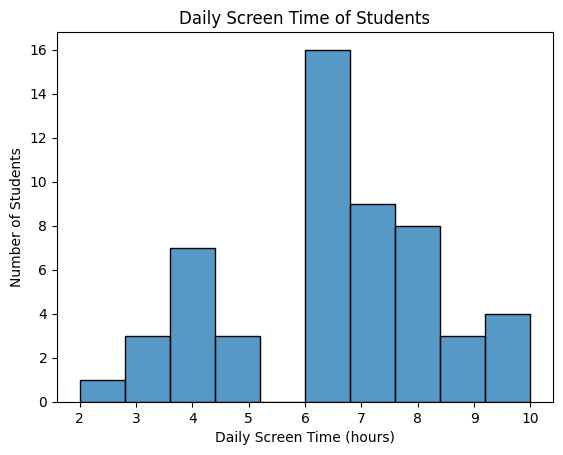

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(screen_time, bins=10)

plt.title("Daily Screen Time of Students")
plt.xlabel("Daily Screen Time (hours)")
plt.ylabel("Number of Students")

plt.show()

In [23]:
screen_time = pd.to_numeric(df["Daily Screen time"], errors="coerce")

count_more_than_6 = (screen_time > 6).sum()

print("Number of students spending more than 6 hours:", count_more_than_6)

Number of students spending more than 6 hours: 0


In [24]:
df["Preferred Programming Language "].value_counts()

Preferred Programming Language 
Python                      44
Java                         3
Java,Python                  2
Python,Java                  1
Java, Python                 1
Java, JavaScript, Python     1
Python, Java                 1
Python,SQL                   1
Name: count, dtype: int64

In [25]:
languages = df["Preferred Programming Language "].dropna().str.lower()

language_counts = {
    "Python": languages.str.contains("python").sum(),
    "Java": languages.str.contains("java").sum(),
    "JavaScript": languages.str.contains("javascript").sum(),
    "SQL": languages.str.contains("sql").sum()
}

language_counts

{'Python': 51, 'Java': 9, 'JavaScript': 1, 'SQL': 1}

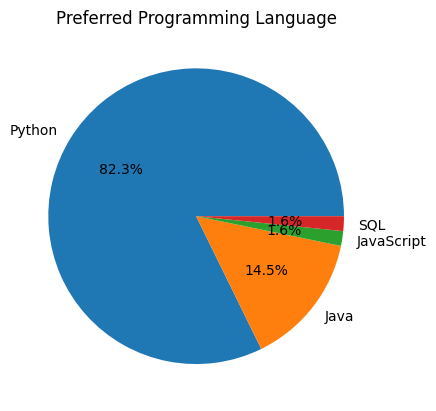

In [26]:
import matplotlib.pyplot as plt

plt.pie(
    language_counts.values(),
    labels=language_counts.keys(),
    autopct="%1.1f%%"
)

plt.title("Preferred Programming Language")
plt.show()

In [27]:
most_preferred = max(language_counts, key=language_counts.get)

print("Most preferred programming language:", most_preferred)
print("Number of students:", language_counts[most_preferred])

Most preferred programming language: Python
Number of students: 51


In [28]:
df[["Study Time", "Sleep Duration "]].head(20)

,Study Time,Sleep Duration
0,2.0 hours,10.0 hours
1,3.0 hours,6.0 hours
2,5.0 hours,7.0 hours
3,5.0 hours,7.0 hours
4,2.0 hours,7.0 hours
5,4.0 hours,7.0 hours
6,4.0 hours,7.0 hours
7,3.0 hours,6.0 hours
8,2.0 hours,6.0 hours
9,3.0 hours,8.0 hours


In [29]:
study_time = pd.to_numeric(df["Study Time"], errors="coerce")

sleep_time = (
    df["Sleep Duration "]
    .str.replace(" hours", "", regex=False)
    .astype(float)
)

In [30]:
print(study_time.head())
print(sleep_time.head())

0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: Study Time, dtype: float64
0    10.0
1     6.0
2     7.0
3     7.0
4     7.0
Name: Sleep Duration , dtype: float64


In [31]:
df["Study Time"].head(20)

0     2.0 hours
1     3.0 hours
2     5.0 hours
3     5.0 hours
4     2.0 hours
5     4.0 hours
6     4.0 hours
7     3.0 hours
8     2.0 hours
9     3.0 hours
10    2.0 hours
11    3.0 hours
12    3.0 hours
13    4.0 hours
14    4.0 hours
15    3.0 hours
16    3.0 hours
17    8.0 hours
18    4.0 hours
19    3.0 hours
Name: Study Time, dtype: object

In [32]:
study_time = (
    df["Study Time"]
    .str.replace(" hours", "", regex=False)
    .astype(float)
)

In [33]:
study_time.head()

0    2.0
1    3.0
2    5.0
3    5.0
4    2.0
Name: Study Time, dtype: float64

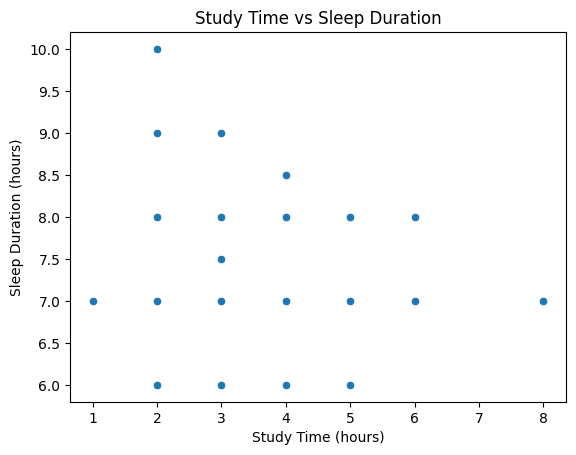

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(x=study_time, y=sleep_time)

plt.title("Study Time vs Sleep Duration")
plt.xlabel("Study Time (hours)")
plt.ylabel("Sleep Duration (hours)")

plt.show()

In [35]:
correlation = study_time.corr(sleep_time)

print("Correlation between Study Time and Sleep Duration:", correlation)

Correlation between Study Time and Sleep Duration: -0.11036189231649733


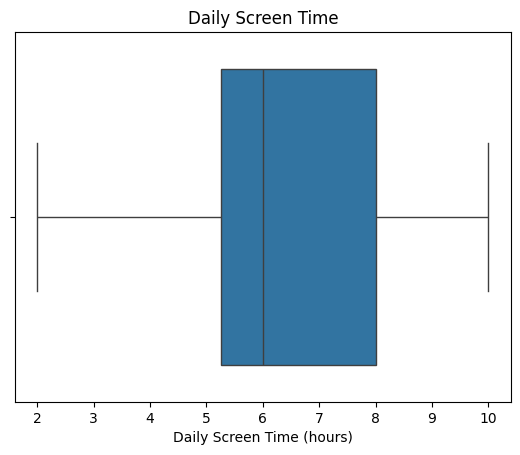

In [37]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

screen_time = (
    df["Daily Screen time"]
    .str.replace(" hours", "", regex=False)
    .astype(float)
)

sns.boxplot(x=screen_time)

plt.title("Daily Screen Time")
plt.xlabel("Daily Screen Time (hours)")

plt.show()

In [38]:
Q1 = screen_time.quantile(0.25)
Q3 = screen_time.quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = screen_time[
    (screen_time < lower_limit) | (screen_time > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Extreme screen-time values:")
print(outliers)

Lower limit: 1.125
Upper limit: 12.125
Extreme screen-time values:
Series([], Name: Daily Screen time, dtype: float64)
